# Offline chess benchmark

This notebook runs locally and does not connect to Lichess or use your token.
Select **Python (ai_course)**. Downloaded engines: **Stockfish 19** and **Sunfish**.
Your bot uses the same material-based minimax search as your Lichess adapter.
Opponents include random moves, Sunfish, and Stockfish skill levels 0, 5, and 10.

Each pair uses the same four-ply seeded opening with colors reversed. Games use **5+0**: each side starts with 300 seconds and receives no additional time after moves. Clocks count actual thinking time; a player that runs out loses on time. Your bot keeps its Lichess clock-aware search and depth cap. Stockfish skill levels are not human Elo ratings. A few games give only a preliminary comparison.


## Earlier fixed-budget benchmark (not 5+0)

10 games; one pair per opponent; 0.05 seconds per move, course depth cap 3, move limit 240 plies, seed 42. All games finished without engine errors. This small sample is preliminary.

| Opponent | Wins | Draws | Losses | Score |
|---|---:|---:|---:|---:|
| random | 1 | 1 | 0 | 75.0% |
| sunfish | 0 | 0 | 2 | 0.0% |
| stockfish_0 | 0 | 0 | 2 | 0.0% |
| stockfish_5 | 0 | 0 | 2 | 0.0% |
| stockfish_10 | 0 | 0 | 2 | 0.0% |

Saved games and details: `offline_results/20261023_043220_472182/`. This snapshot remains separate from new runs.


In [3]:
from pathlib import Path
import sys

CHESS_DIR = Path.cwd()
if not (CHESS_DIR / "offline_arena.py").exists():
    CHESS_DIR = CHESS_DIR / "chess"
if not (CHESS_DIR / "offline_arena.py").exists():
    raise RuntimeError("Open the notebook from ai_course or its chess folder.")
sys.path.insert(0, str(CHESS_DIR))
from offline_arena import run_benchmark


## Run matches
Start with one pair per opponent (10 games). Increase PAIRS for a more useful comparison. Runtime depends on game length and search settings. You can interrupt the cell; completed games are already saved. No minimax scores are printed.


In [7]:
OPPONENTS = ["stockfish_1", "random", "stockfish_0"]
PAIRS = 1
INITIAL_SECONDS = 60  # Five minutes per side
INCREMENT_SECONDS = 0  # No additional time
OUR_SEARCH_DEPTH = 3
MAX_PLIES = 200  # 100 full moves; unfinished games are not draws.

summary, results_dir = run_benchmark(
    opponents=OPPONENTS, pairs=PAIRS,
    initial_seconds=INITIAL_SECONDS, increment=INCREMENT_SECONDS,
    depth=OUR_SEARCH_DEPTH, max_plies=MAX_PLIES, seed=42,
)


stockfish_1 as white: 0-1 (checkmate)
stockfish_1 as black: 1-0 (checkmate)
random as white: 1-0 (checkmate)
random as black: 0-1 (checkmate)
stockfish_0 as white: 0-1 (checkmate)
stockfish_0 as black: 1-0 (checkmate)

Saved results: C:\Users\ritaa\Documents\trying\ai_course\chess\offline_results\20261023_044044_187679


In [8]:
from IPython.display import display, Markdown
import csv

columns = ["opponent", "games", "wins", "draws", "losses", "unfinished", "errors", "score_pct"]
header = " | ".join(columns)
rows = [" | ".join(str(row[c]) if row[c] is not None else "—" for c in columns) for row in summary]
display(Markdown("| " + header + " |\n| " + " | ".join(["---"] * len(columns)) + " |\n" + "\n".join("| " + row + " |" for row in rows)))
print("Score % = (wins + half the draws) / completed games. Excludes unfinished/error games.")
print("PGNs, games.csv, summary.csv, settings.json:", results_dir)


| opponent | games | wins | draws | losses | unfinished | errors | score_pct |
| --- | --- | --- | --- | --- | --- | --- | --- |
| stockfish_1 | 2 | 0 | 0 | 2 | 0 | 0 | 0.0 |
| random | 2 | 2 | 0 | 0 | 0 | 0 | 100.0 |
| stockfish_0 | 2 | 0 | 0 | 2 | 0 | 0 | 0.0 |

Score % = (wins + half the draws) / completed games. Excludes unfinished/error games.
PGNs, games.csv, summary.csv, settings.json: C:\Users\ritaa\Documents\trying\ai_course\chess\offline_results\20261023_044044_187679


## Inspect or replay a game
The PGNs can be opened in any chess viewer. The cell below shows the final position and moves for a saved game. Results are local comparisons, not a Lichess rating estimate.

Engine sources/licenses are kept in `offline_engines/`:
- Stockfish: https://github.com/official-stockfish/Stockfish/releases/tag/sf_19 (GPLv3; source bundled in download).
- Sunfish: https://github.com/thomasahle/sunfish (license included with source).


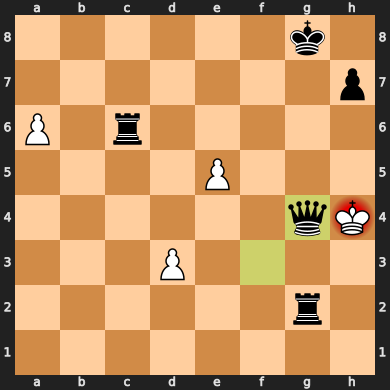

[Event "Offline course benchmark"]
[Site "?"]
[Date "2026.10.23"]
[Round "?"]
[White "CourseMinimax"]
[Black "stockfish_1"]
[Result "0-1"]
[TimeControl "60+0"]
[Termination "checkmate"]

1. Na3 Nh6 2. f3 f6 3. Nb5 { [%clk 0:00:59.975] } 3... d5 { [%clk 0:00:56.666] } 4. h4 { [%clk 0:00:59.929] } 4... a6 { [%clk 0:00:52.817] } 5. Na3 { [%clk 0:00:59.875] } 5... e5 { [%clk 0:00:49.946] } 6. h5 { [%clk 0:00:59.833] } 6... Nf5 { [%clk 0:00:47.818] } 7. Rh3 { [%clk 0:00:59.783] } 7... Bxa3 { [%clk 0:00:46.691] } 8. bxa3 { [%clk 0:00:59.678] } 8... Qe7 { [%clk 0:00:44.644] } 9. Rb1 { [%clk 0:00:59.607] } 9... d4 { [%clk 0:00:42.46] } 10. a4 { [%clk 0:00:59.499] } 10... Be6 { [%clk 0:00:38.023] } 11. Rxb7 { [%clk 0:00:59.372] } 11... Nd6 { [%clk 0:00:29.808] } 12. Rb3 { [%clk 0:00:59.281] } 12... c5 { [%clk 0:00:27.947] } 13. Rh2 { [%clk 0:00:59.167] } 13... Qc7 { [%clk 0:00:26.064] } 14. Rd3 { [%clk 0:00:59.068] } 14... c4 { [%clk 0:00:25.603] } 15. Ra3 { [%clk 0:00:59.004] } 15... O-O { [%c

In [9]:
import chess.pgn
pgn_path = next(results_dir.glob("*.pgn"))  # Choose another PGN here if desired.
with pgn_path.open(encoding="utf-8") as stream:
    saved_game = chess.pgn.read_game(stream)
display(saved_game.end().board())
print(saved_game)
